In [2]:
# =====================================================================
# Part II - Image Colorization
# =====================================================================
#
# Task: take a grayscale image and predict its colors.
#
# The grader will:
#   1. run your model class + load_model() to load your saved weights,
#   2. call colorize() on their own images,
#   3. compare your output to hidden color images (PSNR / MSE).
#
# So the 3 fixed rules below are kept EXACTLY as given -- do not change:
#   1. Weights are saved as a state_dict (torch.save(model.state_dict(), "weights.pth")).
#   2. All images are 256 x 256. colorize() takes/returns numpy ARRAYS, not paths.
#   3. File loading happens OUTSIDE colorize() (see the demo cell at the bottom).
# =====================================================================

# Stage 0: Setup

In [3]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms as T
from torchvision.transforms import functional as TF
from torchvision.datasets import Caltech256


# ---------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ---------------------------------------------------------------------
# Device
# ---------------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("device:", device)


# ---------------------------------------------------------------------
# Fixed assignment convention
# ---------------------------------------------------------------------

IMG_SIZE = 256

device: cuda


# Stage 1: Training and validation data

The training target is the original RGB image.

For every RGB target image, the corresponding model input is generated by
converting that same image to grayscale. Therefore each training pair has the
form

$$
(\text{grayscale image},\ \text{original RGB image}).
$$

A separate validation subset is kept completely out of parameter updates so
that generalisation can be monitored during training.

In [4]:
# =====================================================================
# Dataset
# =====================================================================

DATA_ROOT = "../colorization_data"


rgb_transform = T.Compose([
    T.Lambda(
        lambda img: img.convert("RGB")
    ),
    T.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),
    T.ToTensor(),
])

full_dataset = Caltech256(
    root=DATA_ROOT,
    transform=rgb_transform,
    download=True
)


print(
    "total images:",
    len(full_dataset)
)

100%|██████████| 1.18G/1.18G [00:51<00:00, 22.9MB/s]


total images: 30607


In [5]:
# =====================================================================
# Build grayscale/color pairs and train/validation split
# =====================================================================

class ColorizationDataset(Dataset):
    """
    Wrap a color-image dataset and return:

        gray  : (1, 256, 256), float in [0, 1]
        color : (3, 256, 256), float in [0, 1]
    """

    def __init__(self, base_dataset):
        self.base = base_dataset

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):

        color, _ = self.base[idx]

        gray = TF.rgb_to_grayscale(
            color,
            num_output_channels=1
        )

        return gray, color


# ---------------------------------------------------------------------
# Deterministic subset and validation split
# ---------------------------------------------------------------------

N_TRAIN = 12000
N_VAL = 2000

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    len(full_dataset),
    generator=generator
).tolist()

train_indices = indices[:N_TRAIN]

val_indices = indices[
    N_TRAIN:N_TRAIN + N_VAL
]


train_base = Subset(
    full_dataset,
    train_indices
)

val_base = Subset(
    full_dataset,
    val_indices
)


train_ds = ColorizationDataset(
    train_base
)

val_ds = ColorizationDataset(
    val_base
)


print(
    "train images:",
    len(train_ds)
)

print(
    "validation images:",
    len(val_ds)
)


# ---------------------------------------------------------------------
# Data loaders
# ---------------------------------------------------------------------

BATCH_SIZE = 16

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# ---------------------------------------------------------------------
# Shape sanity check
# ---------------------------------------------------------------------

gray_batch, color_batch = next(
    iter(train_loader)
)

print(
    "gray batch:",
    gray_batch.shape
)

print(
    "color batch:",
    color_batch.shape
)

print(
    "gray range:",
    float(gray_batch.min()),
    "to",
    float(gray_batch.max())
)

print(
    "color range:",
    float(color_batch.min()),
    "to",
    float(color_batch.max())
)

train images: 12000
validation images: 2000
gray batch: torch.Size([16, 1, 256, 256])
color batch: torch.Size([16, 3, 256, 256])
gray range: 0.0 to 0.9999000430107117
color range: 0.0 to 1.0


## Visual sanity check

Before training, a few image pairs are displayed to verify that the model input
is truly grayscale while the target remains the corresponding RGB image.

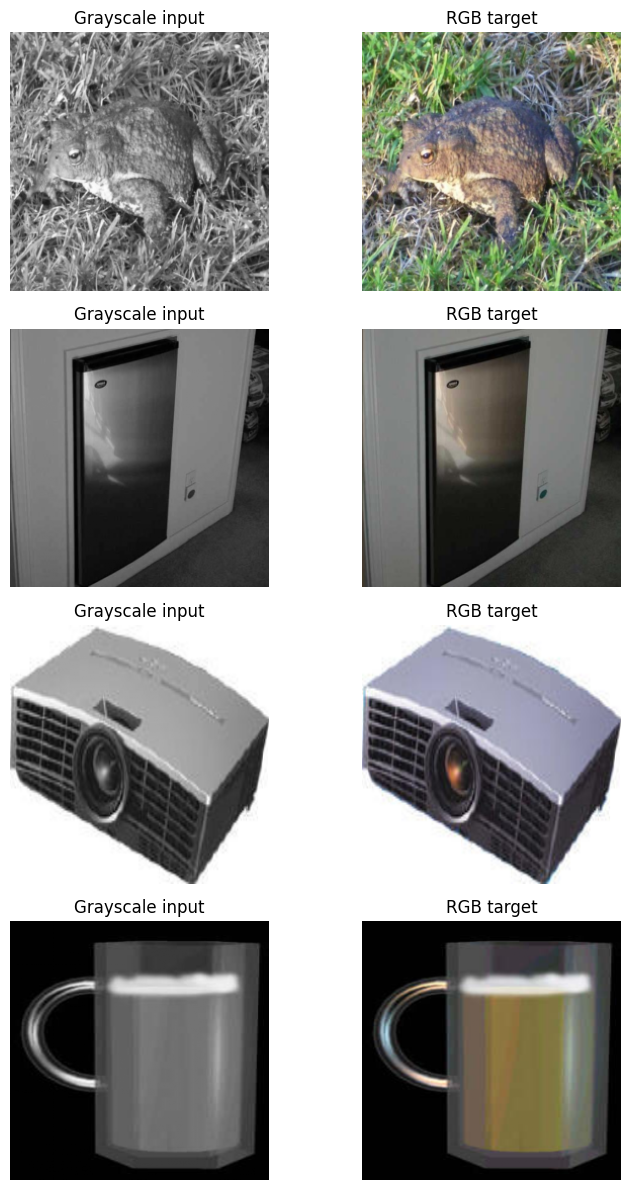

In [6]:
# =====================================================================
# Visual sanity check
# =====================================================================

gray_batch, color_batch = next(iter(train_loader))

n_show = 4

fig, axes = plt.subplots(
    n_show,
    2,
    figsize=(8, 3 * n_show)
)

for i in range(n_show):

    gray_img = gray_batch[i].permute(
        1, 2, 0
    ).numpy()

    color_img = color_batch[i].permute(
        1, 2, 0
    ).numpy()

    axes[i, 0].imshow(
        gray_img.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i, 0].set_title(
        "Grayscale input"
    )

    axes[i, 1].imshow(
        color_img
    )

    axes[i, 1].set_title(
        "RGB target"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# Stage 2: Colorization model

A compact U-Net architecture is used for image colorization.

The encoder learns increasingly abstract image representations, while the
decoder reconstructs the full-resolution RGB image. Skip connections preserve
spatial information such as edges, shapes and object boundaries.

The network follows the required assignment interface:

$$
(1,256,256)\longrightarrow(3,256,256).
$$

A sigmoid output keeps predicted RGB values in the range $[0,1]$.

In [7]:
# =====================================================================
# Colorization model
# =====================================================================

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ColorizeModel(nn.Module):

    def __init__(self):
        super().__init__()

        # -------------------------------------------------------------
        # Encoder
        # -------------------------------------------------------------

        self.enc1 = DoubleConv(
            1, 32
        )

        self.enc2 = DoubleConv(
            32, 64
        )

        self.enc3 = DoubleConv(
            64, 128
        )

        self.pool = nn.MaxPool2d(2)


        # -------------------------------------------------------------
        # Bottleneck
        # -------------------------------------------------------------

        self.bottleneck = DoubleConv(
            128, 256
        )


        # -------------------------------------------------------------
        # Decoder
        # -------------------------------------------------------------

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )


        # -------------------------------------------------------------
        # RGB output
        # -------------------------------------------------------------

        self.output = nn.Conv2d(
            32,
            3,
            kernel_size=1
        )


    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e3)
        )

        # Decoder + skip connections
        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)


        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)


        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)


        return torch.sigmoid(
            self.output(d1)
        )

In [8]:
# =====================================================================
# Model contract sanity check
# =====================================================================

model = ColorizeModel().to(device)

dummy_gray = torch.rand(
    2,
    1,
    IMG_SIZE,
    IMG_SIZE,
    device=device
)

with torch.no_grad():
    dummy_color = model(
        dummy_gray
    )

print(
    "input shape:",
    dummy_gray.shape
)

print(
    "output shape:",
    dummy_color.shape
)

print(
    "output range:",
    float(dummy_color.min()),
    "to",
    float(dummy_color.max())
)


assert dummy_color.shape == (
    2,
    3,
    IMG_SIZE,
    IMG_SIZE
)

assert dummy_color.min() >= 0
assert dummy_color.max() <= 1

print(
    "\nModel contract check passed."
)

input shape: torch.Size([2, 1, 256, 256])
output shape: torch.Size([2, 3, 256, 256])
output range: 0.504819929599762 to 0.5427463054656982

Model contract check passed.


# Stage 3: Model training

The model is trained to reconstruct the original RGB image from its grayscale
version.

An L1 reconstruction loss is used because it is less sensitive to large pixel
errors than MSE and generally produces sharper image reconstructions.

Model parameters are updated only on the training set. After every epoch, the
validation loss is computed separately. The state dictionary with the lowest
validation loss is saved as the final model.

In [9]:
# =====================================================================
# Training configuration
# =====================================================================

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

EPOCHS = 8

WEIGHTS_PATH = "weights.pth"

print("training device:", device)
print("epochs:", EPOCHS)
print("loss:", criterion)
print("weights path:", WEIGHTS_PATH)

training device: cuda
epochs: 8
loss: L1Loss()
weights path: weights.pth


In [10]:
# =====================================================================
# Training and validation helpers
# =====================================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    total_loss = 0.0
    total_images = 0

    for gray, color in loader:

        gray = gray.to(
            device,
            non_blocking=True
        )

        color = color.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        prediction = model(gray)

        loss = criterion(
            prediction,
            color
        )

        loss.backward()

        optimizer.step()

        batch_size = gray.size(0)

        total_loss += (
            loss.item()
            * batch_size
        )

        total_images += batch_size

    return (
        total_loss
        / total_images
    )


@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    total_images = 0

    for gray, color in loader:

        gray = gray.to(
            device,
            non_blocking=True
        )

        color = color.to(
            device,
            non_blocking=True
        )

        prediction = model(gray)

        loss = criterion(
            prediction,
            color
        )

        batch_size = gray.size(0)

        total_loss += (
            loss.item()
            * batch_size
        )

        total_images += batch_size

    return (
        total_loss
        / total_images
    )

In [11]:
# =====================================================================
# Train model and save the best validation checkpoint
# =====================================================================

best_val_loss = float("inf")

train_history = []
val_history = []


for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    val_loss = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_history.append(
        train_loss
    )

    val_history.append(
        val_loss
    )


    improved = (
        val_loss < best_val_loss
    )

    if improved:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            WEIGHTS_PATH
        )


    status = (
        "  <-- saved"
        if improved
        else ""
    )

    print(
        f"epoch {epoch + 1:2d}/{EPOCHS} | "
        f"train L1 = {train_loss:.5f} | "
        f"val L1 = {val_loss:.5f}"
        f"{status}"
    )


print(
    "\nbest validation loss:",
    round(best_val_loss, 6)
)

print(
    "best state_dict saved to:",
    WEIGHTS_PATH
)

epoch  1/8 | train L1 = 0.05994 | val L1 = 0.05254  <-- saved
epoch  2/8 | train L1 = 0.05076 | val L1 = 0.05182  <-- saved
epoch  3/8 | train L1 = 0.05014 | val L1 = 0.05032  <-- saved
epoch  4/8 | train L1 = 0.04984 | val L1 = 0.05002  <-- saved
epoch  5/8 | train L1 = 0.04958 | val L1 = 0.05029
epoch  6/8 | train L1 = 0.04940 | val L1 = 0.05202
epoch  7/8 | train L1 = 0.04933 | val L1 = 0.05081
epoch  8/8 | train L1 = 0.04917 | val L1 = 0.04978  <-- saved

best validation loss: 0.049776
best state_dict saved to: weights.pth


In [12]:
# =====================================================================
# Stage 3b: Safe refinement from the best saved checkpoint
# =====================================================================

REFINED_WEIGHTS_PATH = "weights_refined.pth"

refined_model = ColorizeModel().to(device)

refined_model.load_state_dict(
    torch.load(
        WEIGHTS_PATH,
        map_location=device
    )
)

refined_model.eval()

refined_criterion = nn.L1Loss()

refined_optimizer = torch.optim.Adam(
    refined_model.parameters(),
    lr=3e-4
)

REFINE_EPOCHS = 6

best_refined_val = evaluate(
    refined_model,
    val_loader,
    refined_criterion,
    device
)

# Save the starting checkpoint as a valid fallback.
# If refinement does not improve validation loss,
# this remains the best available checkpoint.
torch.save(
    refined_model.state_dict(),
    REFINED_WEIGHTS_PATH
)

print(
    "starting validation L1:",
    round(best_refined_val, 6)
)

for epoch in range(REFINE_EPOCHS):

    train_loss = train_one_epoch(
        refined_model,
        train_loader,
        refined_optimizer,
        refined_criterion,
        device
    )

    val_loss = evaluate(
        refined_model,
        val_loader,
        refined_criterion,
        device
    )

    saved = ""

    if val_loss < best_refined_val:

        best_refined_val = val_loss

        torch.save(
            refined_model.state_dict(),
            REFINED_WEIGHTS_PATH
        )

        saved = "  <-- saved"

    print(
        f"refine epoch {epoch + 1:2d}/{REFINE_EPOCHS} | "
        f"train L1 = {train_loss:.5f} | "
        f"val L1 = {val_loss:.5f}"
        f"{saved}"
    )

print(
    "\nbest refined validation loss:",
    round(best_refined_val, 6)
)

print(
    "refined weights:",
    REFINED_WEIGHTS_PATH
)

starting validation L1: 0.049776
refine epoch  1/6 | train L1 = 0.04824 | val L1 = 0.04905  <-- saved
refine epoch  2/6 | train L1 = 0.04808 | val L1 = 0.04882  <-- saved
refine epoch  3/6 | train L1 = 0.04805 | val L1 = 0.04881  <-- saved
refine epoch  4/6 | train L1 = 0.04794 | val L1 = 0.04857  <-- saved
refine epoch  5/6 | train L1 = 0.04778 | val L1 = 0.04853  <-- saved
refine epoch  6/6 | train L1 = 0.04766 | val L1 = 0.04825  <-- saved

best refined validation loss: 0.048246
refined weights: weights_refined.pth


In [13]:
import shutil

shutil.copyfile(
    "weights_refined.pth",
    "weights.pth"
)

print("final submission weights saved to: weights.pth")

final submission weights saved to: weights.pth


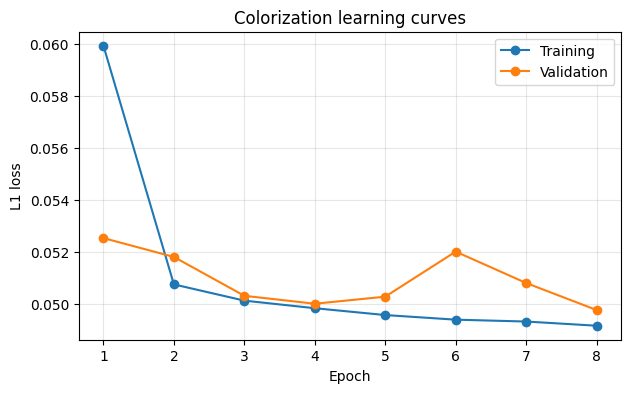

In [14]:
# =====================================================================
# Learning curves
# =====================================================================

epochs_axis = range(
    1,
    len(train_history) + 1
)

plt.figure(
    figsize=(7, 4)
)

plt.plot(
    epochs_axis,
    train_history,
    marker="o",
    label="Training"
)

plt.plot(
    epochs_axis,
    val_history,
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("L1 loss")
plt.title(
    "Colorization learning curves"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Stage 4: Submission interface: `load_model` and `colorize`

These two functions implement the fixed inference interface used by the grader.

`load_model()` rebuilds the network and loads the saved `state_dict`, while
`colorize()` receives a 256 × 256 grayscale NumPy array and returns a
256 × 256 × 3 RGB NumPy array.

In [15]:
def load_model(weights_path="weights.pth"):
    model = ColorizeModel()
    model.load_state_dict(torch.load(weights_path, map_location="cpu"))
    model.eval()
    return model


def colorize(gray_img, model):
    # gray_img: numpy array, shape (256, 256), float in [0, 1]
    x = torch.from_numpy(gray_img).float().view(1, 1, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        y = model(x)                # (1, 3, 256, 256)
    out = y.squeeze(0).permute(1, 2, 0).cpu().numpy()   # (256, 256, 3)
    return np.clip(out, 0.0, 1.0)

# Stage 5: Held-out validation examples and final inference check

The saved model is loaded from disk using the same interface that will be used
at grading time. Predictions are then generated for images from the validation
set that were not used for parameter updates.

Each example compares the grayscale input, the model prediction and the
original RGB target.

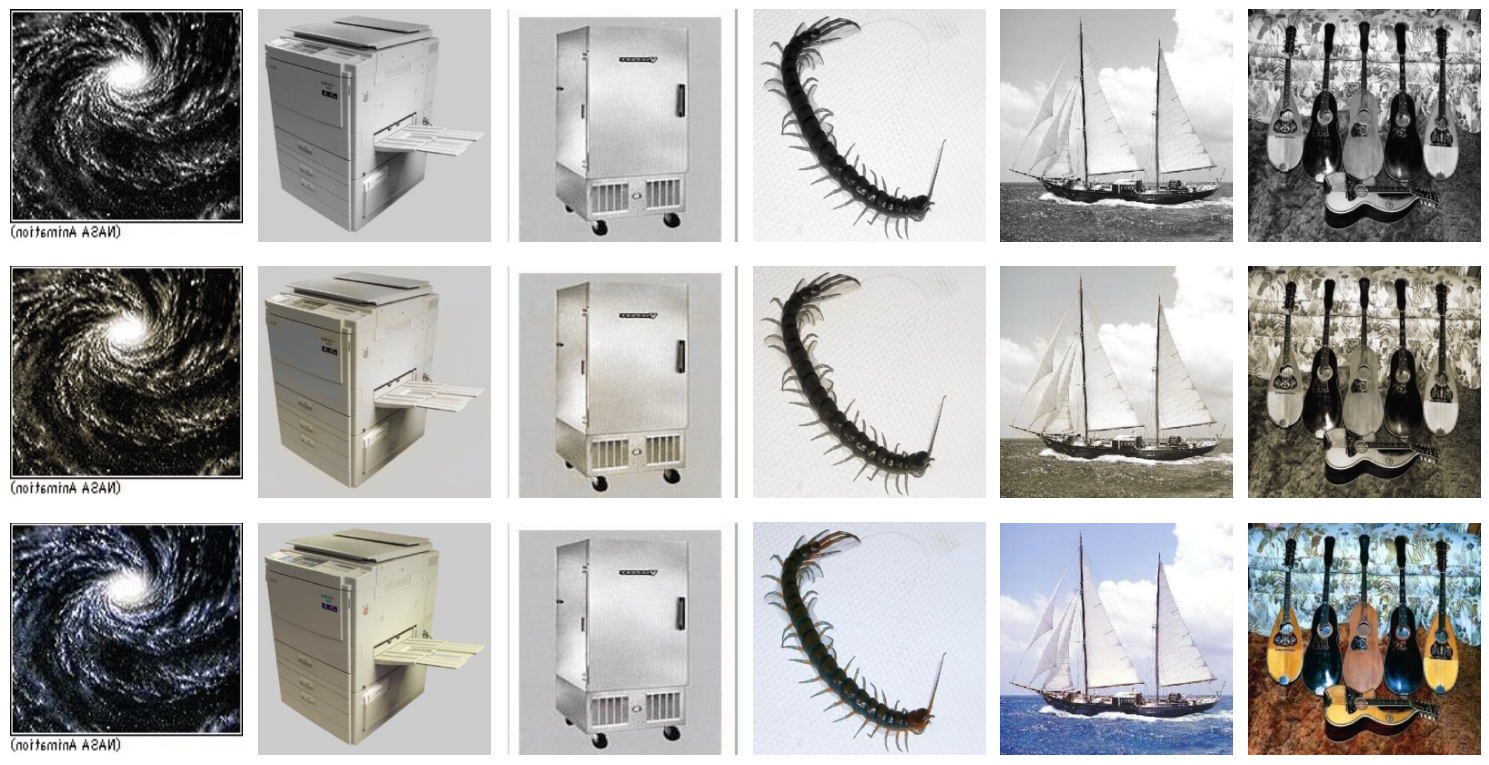

In [16]:
demo_model = load_model("weights.pth")

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for col in range(6):
    gray_t, color_t = val_ds[col]
    gray_np = gray_t.squeeze(0).numpy()          # (256, 256)
    color_np = color_t.permute(1, 2, 0).numpy()  # (256, 256, 3)
    pred_np = colorize(gray_np, demo_model)       # (256, 256, 3)

    axes[0, col].imshow(gray_np, cmap="gray"); axes[0, col].axis("off")
    axes[1, col].imshow(pred_np); axes[1, col].axis("off")
    axes[2, col].imshow(color_np); axes[2, col].axis("off")

axes[0, 0].set_ylabel("grayscale input", fontsize=10)
axes[1, 0].set_ylabel("model output", fontsize=10)
axes[2, 0].set_ylabel("ground truth", fontsize=10)
plt.tight_layout()
plt.show()

In [17]:
# =====================================================================
# Final quantitative validation
# =====================================================================

eval_model = load_model(
    WEIGHTS_PATH
).to(device)

eval_model.eval()

model_sq_error = 0.0
gray_sq_error = 0.0
num_values = 0

with torch.no_grad():

    for gray, color in val_loader:

        gray = gray.to(
            device,
            non_blocking=True
        )

        color = color.to(
            device,
            non_blocking=True
        )

        prediction = eval_model(gray)

        # Simple baseline:
        # use the grayscale image as all three RGB channels.
        gray_rgb = gray.repeat(
            1, 3, 1, 1
        )

        model_sq_error += (
            (prediction - color)
            .pow(2)
            .sum()
            .item()
        )

        gray_sq_error += (
            (gray_rgb - color)
            .pow(2)
            .sum()
            .item()
        )

        num_values += color.numel()


model_mse = (
    model_sq_error
    / num_values
)

gray_mse = (
    gray_sq_error
    / num_values
)

model_psnr = (
    10
    * np.log10(
        1.0 / model_mse
    )
)

gray_psnr = (
    10
    * np.log10(
        1.0 / gray_mse
    )
)


print(
    "model validation MSE:",
    round(model_mse, 6)
)

print(
    "model validation PSNR:",
    round(model_psnr, 3),
    "dB"
)

print(
    "\ngrayscale baseline MSE:",
    round(gray_mse, 6)
)

print(
    "grayscale baseline PSNR:",
    round(gray_psnr, 3),
    "dB"
)

print(
    "\nMSE improvement over grayscale:",
    round(
        100
        * (
            gray_mse - model_mse
        )
        / gray_mse,
        2
    ),
    "%"
)

model validation MSE: 0.007795
model validation PSNR: 21.082 dB

grayscale baseline MSE: 0.008974
grayscale baseline PSNR: 20.47 dB

MSE improvement over grayscale: 13.14 %


# Final Summary

This notebook implements the complete image-colorization pipeline required in
Part II of the assignment.

## Data

- The Caltech256 dataset was used as the image source.
- The full dataset contains 30,607 images.
- A deterministic subset of 12,000 images was used for training.
- A separate held-out subset of 2,000 images was used for validation.
- Each RGB image was resized to 256 × 256.
- The model input was generated by converting the RGB image to a single-channel
  grayscale image.
- The original RGB image was kept as the prediction target.
- The validation images were not used for parameter updates.

## Model

- A compact U-Net architecture was implemented.
- The network receives a grayscale tensor of shape:

  `(1, 256, 256)`

  and predicts an RGB tensor of shape:

  `(3, 256, 256)`.

- Skip connections are used to preserve spatial information such as edges,
  shapes and object boundaries.
- A sigmoid output layer keeps predicted RGB values in the range `[0, 1]`.

## Training

- The model was trained on GPU when available.
- L1 reconstruction loss was used.
- Adam optimization was used with an initial learning rate of `1e-3`.
- The initial model was trained for 8 epochs.
- After every epoch, validation loss was evaluated separately.
- The checkpoint with the lowest validation loss was saved using
  `state_dict`.

The best validation L1 loss from the initial training stage was:

`0.049776`

## Refinement

A second fine-tuning stage was performed starting from the best saved
checkpoint.

- Adam optimizer with learning rate `3e-4`.
- 6 additional refinement epochs.
- The best refined checkpoint was selected according to validation L1 loss.

The best refined validation loss was:

`0.048246`

The refined checkpoint was then promoted to `weights.pth`, which is the final
model used by the submission interface.

## Submission Interface

The notebook provides the required functions:

- `load_model(weights_path)` reconstructs `ColorizeModel` and loads the saved
  `state_dict`.
- `colorize(gray_img, model)` accepts a NumPy grayscale image and returns a
  NumPy RGB image.
- Input images have size `256 × 256`.
- Output images have size `256 × 256 × 3`.
- File loading is performed outside `colorize()`.

## Final Validation

The final saved model was evaluated on the held-out validation set.

Final model:

- Validation MSE: `0.007795`
- Validation PSNR: `21.082 dB`

Grayscale baseline:

- Validation MSE: `0.008974`
- Validation PSNR: `20.470 dB`

The final colorization model therefore reduced MSE by approximately:

`13.14%`

relative to simply copying the grayscale input into the three RGB channels.

The final `weights.pth` contains the refined model and is compatible with the
required `load_model()` and `colorize()` submission interface.